In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_absolute_error , mean_squared_error ,r2_score
import os

DATA_PATH = '../data/eda_output.csv' if os.path.exists('../data/eda_output.csv') else 'data/eda_output.csv'
df = pd.read_csv(DATA_PATH)

df.head(10)

,order_id,customer_id,store_id,order_timestamp,delivery_timestamp,order_value,delivery_time_minutes,hour_of_day,weekday_number,day_of_week,date,is_weekend,customer_satisfaction,satisfaction_score
0,sdv-id-PPcBpb,C018496,DS007,2026-05-29 11:30:12,2026-05-29 11:40:14,204.0,10.033333,11,5,Friday,2026-05-29,0,Not Satisfied,0.0
1,sdv-id-NdEuVy,C006527,DS015,2026-07-15 00:01:52,2026-07-15 00:06:52,710.0,5.000000,0,3,Wednesday,2026-07-15,0,Satisfied,0.5
2,sdv-id-kPbvnT,C008719,DS007,2026-07-23 10:39:54,2026-07-23 10:49:54,251.0,10.000000,10,4,Thursday,2026-07-23,0,Satisfied,0.0
3,sdv-id-JrFXLd,C013876,DS002,2026-06-02 02:06:09,2026-06-02 02:12:09,529.0,6.000000,2,2,Tuesday,2026-06-02,0,Satisfied,0.4
4,sdv-id-rNMsjf,C011488,DS005,2026-07-03 07:43:44,2026-07-03 07:49:44,515.0,6.000000,7,5,Friday,2026-07-03,0,Satisfied,0.4
5,sdv-id-YdxfnV,C006400,DS013,2026-02-03 07:14:02,2026-02-03 07:18:02,768.0,4.000000,7,2,Tuesday,2026-02-03,0,Satisfied,0.6
6,sdv-id-WZqOBZ,C012274,DS011,2026-01-30 06:31:39,2026-01-30 06:37:39,2442.0,6.000000,6,5,Friday,2026-01-30,0,Satisfied,0.4
7,sdv-id-MxmlhI,C002128,DS009,2026-05-22 08:09:36,2026-05-22 08:15:36,883.0,6.000000,8,5,Friday,2026-05-22,0,Satisfied,0.4
8,sdv-id-sBgmlK,C004954,DS014,2026-07-16 14:45:19,2026-07-16 14:51:19,680.0,6.000000,14,4,Thursday,2026-07-16,0,Satisfied,0.4
9,sdv-id-DhETWS,C006702,DS010,2026-05-18 15:21:33,2026-05-18 15:27:33,1286.0,6.000000,15,1,Monday,2026-05-18,0,Satisfied,0.4


1. Feature Engineering

In [15]:
df["order_timestamp"] = pd.to_datetime(df["order_timestamp"])
df["date"] = df["order_timestamp"].dt.normalize()

df["hour_of_day"] = df["order_timestamp"].dt.hour
df["weekday_number"] = df["order_timestamp"].dt.dayofweek

df["hour_sin"] = np.sin(2 * np.pi * df["hour_of_day"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour_of_day"] / 24)
df["weekday_sin"] = np.sin(2 * np.pi * df["weekday_number"] / 7)
df["weekday_cos"] = np.cos(2 * np.pi * df["weekday_number"] / 7)

df["is_peak_hour"] = (
    (((df["hour_of_day"] >= 7) & (df["hour_of_day"] <= 9)) |
     ((df["hour_of_day"] >= 17) & (df["hour_of_day"] <= 19)))
).astype(int)

2. Hourly Demand

In [16]:
hourly = (
    df.set_index("order_timestamp")
      .resample("h")
      .agg(
          order_count=("order_id", "size"),
          order_value=("order_value", "sum"),
          avg_delivery_time=("delivery_time_minutes", "mean"),
          satisfaction_score=("satisfaction_score", "mean"),
      )
      .reset_index()
      .sort_values("order_timestamp")
)

hourly["order_count"] = hourly["order_count"].fillna(0)
hourly["order_value"] = hourly["order_value"].fillna(0)
hourly["avg_delivery_time"] = hourly["avg_delivery_time"].ffill().bfill()
hourly["satisfaction_score"] = hourly["satisfaction_score"].ffill().bfill()

hourly["hour"] = hourly["order_timestamp"].dt.hour
hourly["weekday"] = hourly["order_timestamp"].dt.dayofweek
hourly["is_weekend"] = hourly["weekday"].isin([5, 6]).astype(int)

hourly["lag_1"] = hourly["order_count"].shift(1)
hourly["lag_24"] = hourly["order_count"].shift(24)
hourly["rolling_3"] = hourly["order_count"].shift(1).rolling(3).mean()
hourly["rolling_24"] = hourly["order_count"].shift(1).rolling(24).mean()

hourly["hour_sin"] = np.sin(2 * np.pi * hourly["hour"] / 24)
hourly["hour_cos"] = np.cos(2 * np.pi * hourly["hour"] / 24)
hourly["weekday_sin"] = np.sin(2 * np.pi * hourly["weekday"] / 7)
hourly["weekday_cos"] = np.cos(2 * np.pi * hourly["weekday"] / 7)

hourly = hourly.dropna().reset_index(drop=True)

3. Daily Demand

In [17]:
daily = (
    df.set_index("date")
      .resample("D")
      .agg(
          order_count=("order_id", "size"),
          order_value=("order_value", "sum"),
          avg_delivery_time=("delivery_time_minutes", "mean"),
          satisfaction_score=("satisfaction_score", "mean"),
      )
      .reset_index()
      .sort_values("date")
)

daily["order_count"] = daily["order_count"].fillna(0)
daily["order_value"] = daily["order_value"].fillna(0)
daily["avg_delivery_time"] = daily["avg_delivery_time"].ffill().bfill()
daily["satisfaction_score"] = daily["satisfaction_score"].ffill().bfill()

daily["lag_1"] = daily["order_count"].shift(1)
daily["lag_7"] = daily["order_count"].shift(7)
daily["rolling_7"] = daily["order_count"].shift(1).rolling(7).mean()
daily["rolling_14"] = daily["order_count"].shift(1).rolling(14).mean()

daily["weekday"] = daily["date"].dt.dayofweek
daily["is_weekend"] = daily["weekday"].isin([5, 6]).astype(int)
daily["weekday_sin"] = np.sin(2 * np.pi * daily["weekday"] / 7)
daily["weekday_cos"] = np.cos(2 * np.pi * daily["weekday"] / 7)

daily = daily.dropna().reset_index(drop=True)

In [18]:
daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197 entries, 0 to 196
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   date                197 non-null    datetime64[ns]
 1   order_count         197 non-null    int64         
 2   order_value         197 non-null    float64       
 3   avg_delivery_time   197 non-null    float64       
 4   satisfaction_score  197 non-null    float64       
 5   lag_1               197 non-null    float64       
 6   lag_7               197 non-null    float64       
 7   rolling_7           197 non-null    float64       
 8   rolling_14          197 non-null    float64       
 9   weekday             197 non-null    int32         
 10  is_weekend          197 non-null    int64         
 11  weekday_sin         197 non-null    float64       
 12  weekday_cos         197 non-null    float64       
dtypes: datetime64[ns](1), float64(9), int32(1), int64(

In [19]:
# Chronological split: 70% train, 15% validation, 15% test
hourly = hourly.sort_values("order_timestamp").reset_index(drop=True)
daily = daily.sort_values("date").reset_index(drop=True)

hourly_train_end = int(len(hourly) * 0.70)
hourly_val_end = int(len(hourly) * 0.85)

train_hourly = hourly.iloc[:hourly_train_end].copy()
val_hourly = hourly.iloc[hourly_train_end:hourly_val_end].copy()
test_hourly = hourly.iloc[hourly_val_end:].copy()

daily_train_end = int(len(daily) * 0.70)
daily_val_end = int(len(daily) * 0.85)

train_daily = daily.iloc[:daily_train_end].copy()
val_daily = daily.iloc[daily_train_end:daily_val_end].copy()
test_daily = daily.iloc[daily_val_end:].copy()

print("Hourly:", train_hourly.shape, val_hourly.shape, test_hourly.shape)
print("Daily:", train_daily.shape, val_daily.shape, test_daily.shape)

Hourly: (3528, 16) (756, 16) (756, 16)
Daily: (137, 13) (30, 13) (30, 13)


In [20]:
test_daily.head(4)


,date,order_count,order_value,avg_delivery_time,satisfaction_score,lag_1,lag_7,rolling_7,rolling_14,weekday,is_weekend,weekday_sin,weekday_cos
167,2026-07-01,5242,2886368.0,6.900639,0.324353,5223.0,4912.0,5194.000000,4756.642857,2,0,0.974928,-0.222521
168,2026-07-02,5043,2636359.0,6.928439,0.321580,5242.0,5126.0,5241.142857,4857.785714,3,0,0.433884,-0.900969
169,2026-07-03,5212,2689531.0,6.957985,0.319053,5043.0,5185.0,5229.285714,4936.428571,4,0,-0.433884,-0.900969
170,2026-07-04,4934,2585954.0,6.928223,0.321783,5212.0,5372.0,5233.142857,5010.214286,5,1,-0.974928,-0.222521


4. Naive Baseline Model

[]

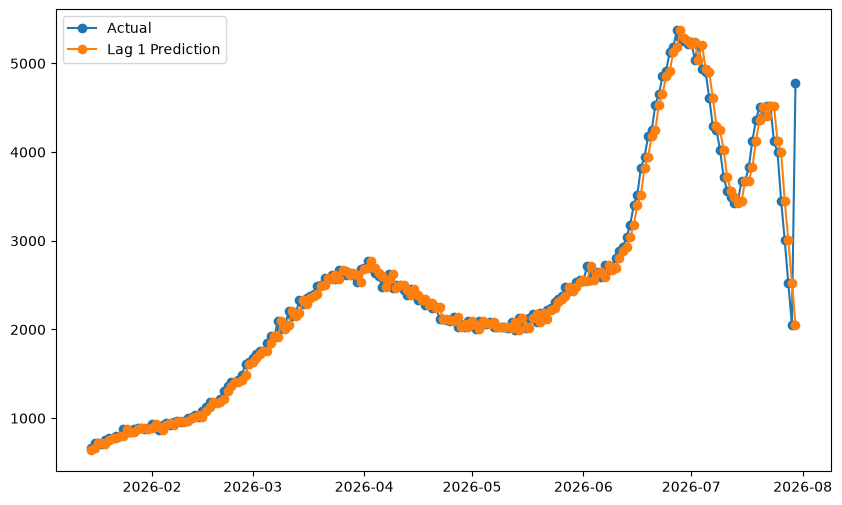

In [21]:
# hourly lag 1 outcome
plt.figure(figsize=(10, 6))
plt.plot(daily['date'], daily['order_count'], label="Actual",marker='o')
plt.plot(daily['date'] , daily['lag_1'], label="Lag 1 Prediction",marker='o')
plt.legend()
plt.plot()


5. Baseline Model

In [22]:

hourly_features = [
    "hour", "weekday", "is_weekend",
    "hour_sin", "hour_cos",
    "weekday_sin", "weekday_cos",
    "lag_1", "lag_24", "rolling_3", "rolling_24",
]

daily_features = [
    "weekday", "is_weekend",
    "weekday_sin", "weekday_cos",
    "lag_1", "lag_7", "rolling_7", "rolling_14",
]

def train_and_eval(train, test, features):
    model = xgb.XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1,
    )

    model.fit(train[features], train["order_count"])
    predictions = model.predict(test[features])

    mae = mean_absolute_error(test["order_count"], predictions)
    rmse = np.sqrt(mean_squared_error(test["order_count"], predictions))
    r2 = r2_score(test["order_count"], predictions)
    sum_actual = np.sum(test["order_count"])
    wape = (np.sum(np.abs(test["order_count"] - predictions)) / sum_actual) * 100 if sum_actual > 0 else 0.0
    accuracy = max(0.0, 100.0 - wape)

    return model, predictions, mae, rmse, r2, wape, accuracy


baseline_hourly_train = pd.concat([train_hourly, val_hourly])
baseline_daily_train = pd.concat([train_daily, val_daily])

hourly_model, hourly_preds, hourly_mae, hourly_rmse, hourly_r2, hourly_wape, hourly_acc = train_and_eval(
    baseline_hourly_train, test_hourly, hourly_features
)

daily_model, daily_preds, daily_mae, daily_rmse, daily_r2, daily_wape, daily_acc = train_and_eval(
    baseline_daily_train, test_daily, daily_features
)

print("=== Baseline Hourly Evaluation ===")
print(f"Hourly Forecast Accuracy : {hourly_acc:.1f}%")
print(f"Hourly WAPE              : {hourly_wape:.1f}%")
print("Hourly MAE               :", hourly_mae)
print("Hourly RMSE              :", hourly_rmse)
print("Hourly R²                :", hourly_r2)

print("\n=== Baseline Daily Evaluation (Supply Chain Benchmark) ===")
print(f"Daily Forecast Accuracy  : {daily_acc:.1f}% (Operational Benchmark)")
print(f"Daily WAPE               : {daily_wape:.1f}%")
print("Daily MAE                :", daily_mae)
print("Daily RMSE               :", daily_rmse)
print("Daily R²                 :", daily_r2)

Baseline hourly MAE: 17.341590881347656
Baseline hourly RMSE: 117.03545970399313
Baseline hourly R²: 0.026979804039001465
Baseline daily MAE: 326.2940979003906
Baseline daily RMSE: 568.3483196948857
Baseline daily R²: 0.4177206754684448


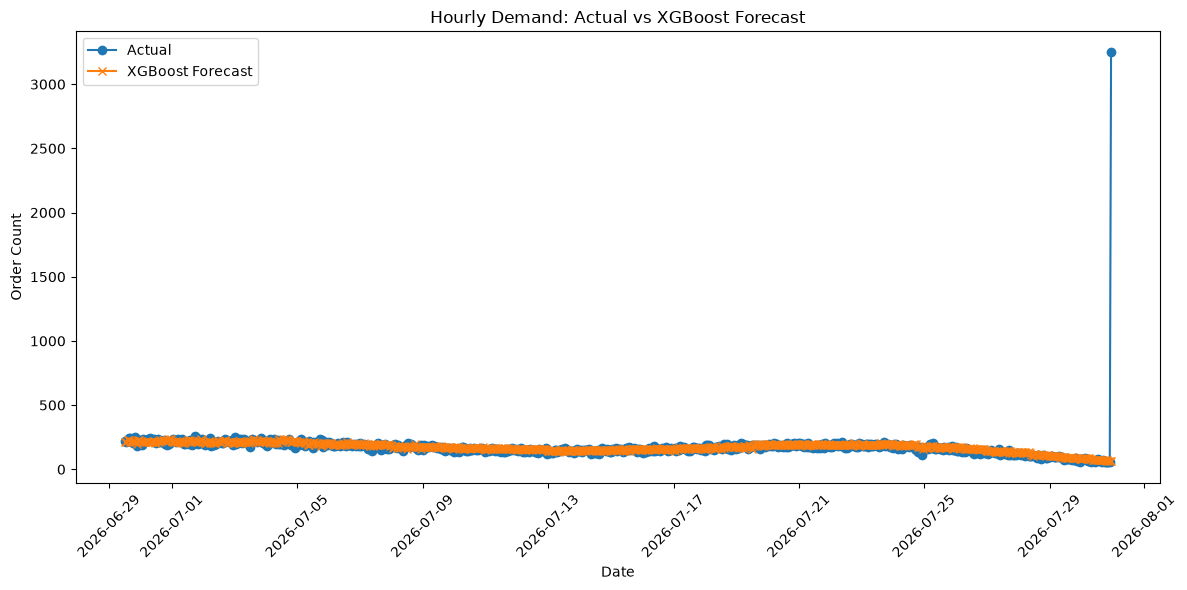

In [23]:
# actual/predicted comparison (Hourly)
plt.figure(figsize=(12, 6))
plt.plot(test_hourly['order_timestamp'], test_hourly['order_count'], label='Actual', marker='o')
plt.plot(test_hourly['order_timestamp'], hourly_preds, label='XGBoost Forecast', marker='x')
plt.title('Hourly Demand: Actual vs XGBoost Forecast')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

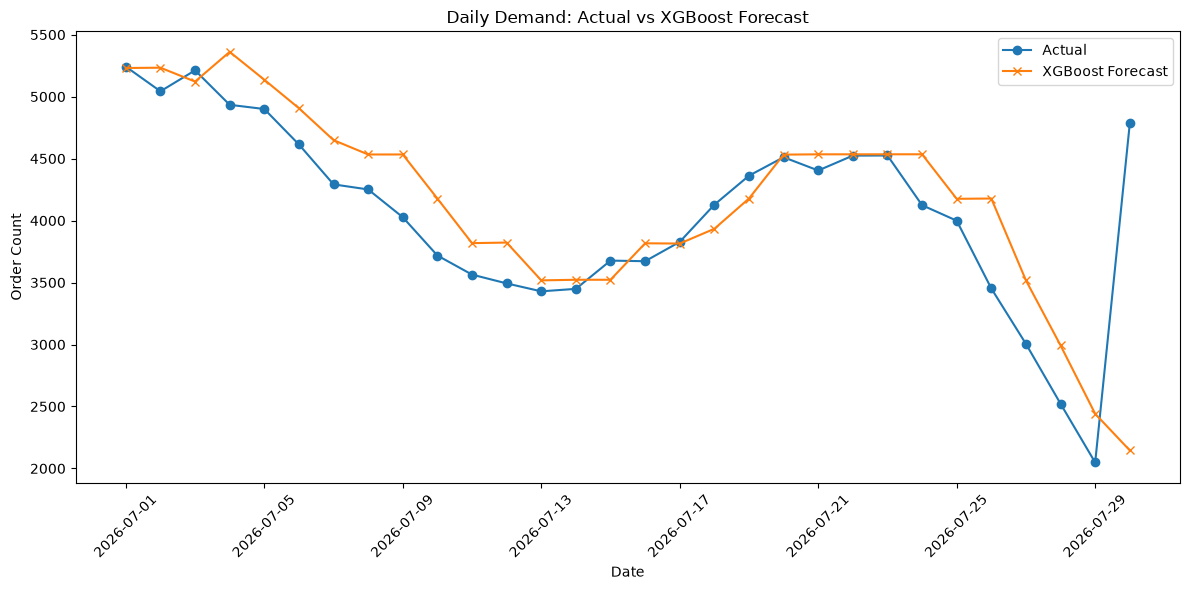

In [24]:
# actual/predicted comparison (Daily)
plt.figure(figsize=(12, 6))
plt.plot(test_daily['date'], test_daily['order_count'], label='Actual', marker='o')
plt.plot(test_daily['date'], daily_preds, label='XGBoost Forecast', marker='x')
plt.title('Daily Demand: Actual vs XGBoost Forecast')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

5. Model Tuning 

In [25]:
X_train = train_hourly[hourly_features]
y_train = train_hourly["order_count"]

X_val = val_hourly[hourly_features]
y_val = val_hourly["order_count"]

X_test = test_hourly[hourly_features]
y_test = test_hourly["order_count"]

In [26]:
#Tuning using RandomizedSearchCV with TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

param_dist = {
    "n_estimators": [200, 400, 600],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0],
    "min_child_weight": [1, 3, 5]
}

model = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1,
)

tscv = TimeSeriesSplit(n_splits=3)

search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_dist,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train)
print(search.best_params_)

{'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


In [27]:
best_model = search.best_estimator_
val_pred = best_model.predict(X_val)

mae = mean_absolute_error(y_val, val_pred)
rmse = np.sqrt(mean_squared_error(y_val, val_pred))

print("Hourly Validation MAE:", mae)
print("Hourly Validation RMSE:", rmse)

Hourly Validation MAE: 41.260009765625
Hourly Validation RMSE: 57.01327199515697


In [28]:
hourly_final_model = search.best_estimator_

hourly_final_model.fit(
    pd.concat([X_train, X_val]),
    pd.concat([y_train, y_val]),
)

test_pred_hourly = hourly_final_model.predict(X_test)

hourly_test_mae = mean_absolute_error(y_test, test_pred_hourly)
hourly_test_rmse = np.sqrt(mean_squared_error(y_test, test_pred_hourly))
hourly_test_r2 = r2_score(y_test, test_pred_hourly)

print("Tuned hourly MAE:", hourly_test_mae)
print("Tuned hourly RMSE:", hourly_test_rmse)
print("Tuned hourly R²:", hourly_test_r2)

Tuned hourly MAE: 16.61757469177246
Tuned hourly RMSE: 117.08024675276141
Tuned hourly R²: 0.026234984397888184


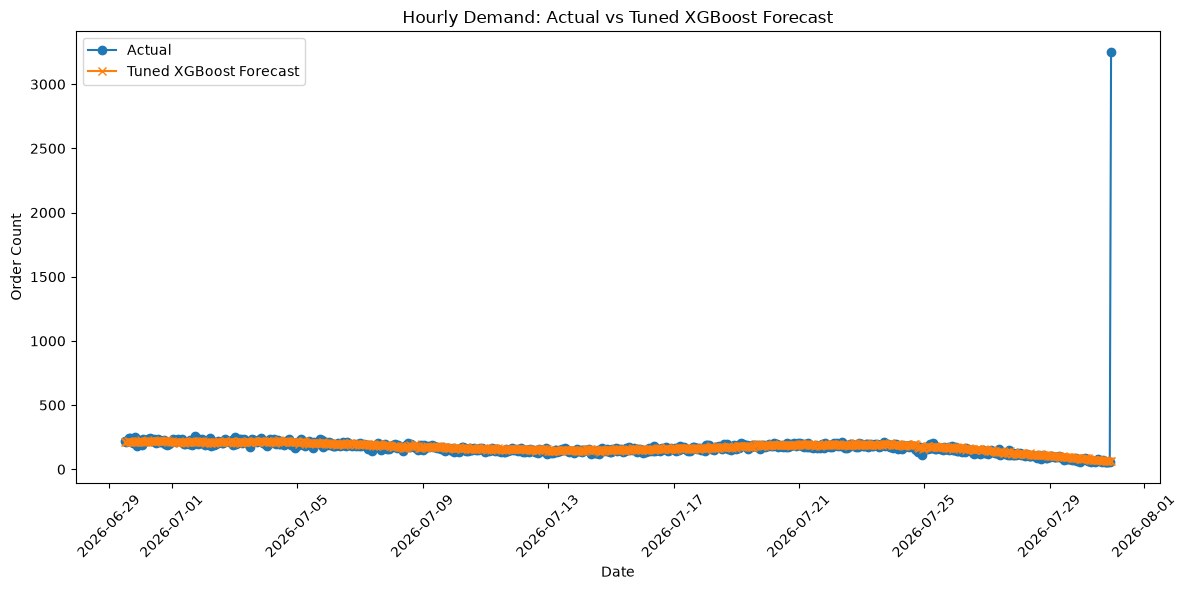

In [29]:
#tuned Xgboost forecast vs actual
plt.figure(figsize=(12, 6))
plt.plot(test_hourly['order_timestamp'], y_test, label='Actual', marker='o')
plt.plot(test_hourly['order_timestamp'], test_pred_hourly, label='Tuned XGBoost Forecast', marker='x')
plt.title('Hourly Demand: Actual vs Tuned XGBoost Forecast')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
X_train_daily = train_daily[daily_features]
y_train_daily = train_daily["order_count"]

X_val_daily = val_daily[daily_features]
y_val_daily = val_daily["order_count"]

X_test_daily = test_daily[daily_features]
y_test_daily = test_daily["order_count"]

In [31]:
param_dist = {
    "n_estimators": [200, 400, 600],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.01, 0.05, 0.1],
    "subsample": [0.7, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0],
    "min_child_weight": [1, 3, 5]
}

daily_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=1,
)

tscv = TimeSeriesSplit(n_splits=3)

daily_search = RandomizedSearchCV(
    estimator=daily_model,
    param_distributions=param_dist,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

daily_search.fit(X_train_daily, y_train_daily)
best_daily_model = daily_search.best_estimator_

In [32]:
# validation metrics
val_daily_pred = best_daily_model.predict(X_val_daily)
val_daily_mae = mean_absolute_error(y_val_daily, val_daily_pred)
val_daily_rmse = np.sqrt(mean_squared_error(y_val_daily, val_daily_pred))

print("Validation Daily MAE:", val_daily_mae)
print("Validation Daily RMSE:", val_daily_rmse)

Validation Daily MAE: 1152.3341064453125
Validation Daily RMSE: 1561.0308292919779


In [33]:
daily_final_model = daily_search.best_estimator_

daily_final_model.fit(
    pd.concat([X_train_daily, X_val_daily]),
    pd.concat([y_train_daily, y_val_daily]),
)

test_daily_pred = daily_final_model.predict(X_test_daily)

daily_test_mae = mean_absolute_error(y_test_daily, test_daily_pred)
daily_test_rmse = np.sqrt(mean_squared_error(y_test_daily, test_daily_pred))
daily_test_r2 = r2_score(y_test_daily, test_daily_pred)

print("Tuned daily MAE:", daily_test_mae)
print("Tuned daily RMSE:", daily_test_rmse)
print("Tuned daily R²:", daily_test_r2)

Tuned daily MAE: 327.1297302246094
Tuned daily RMSE: 573.4012829162488
Tuned daily R²: 0.4073209762573242


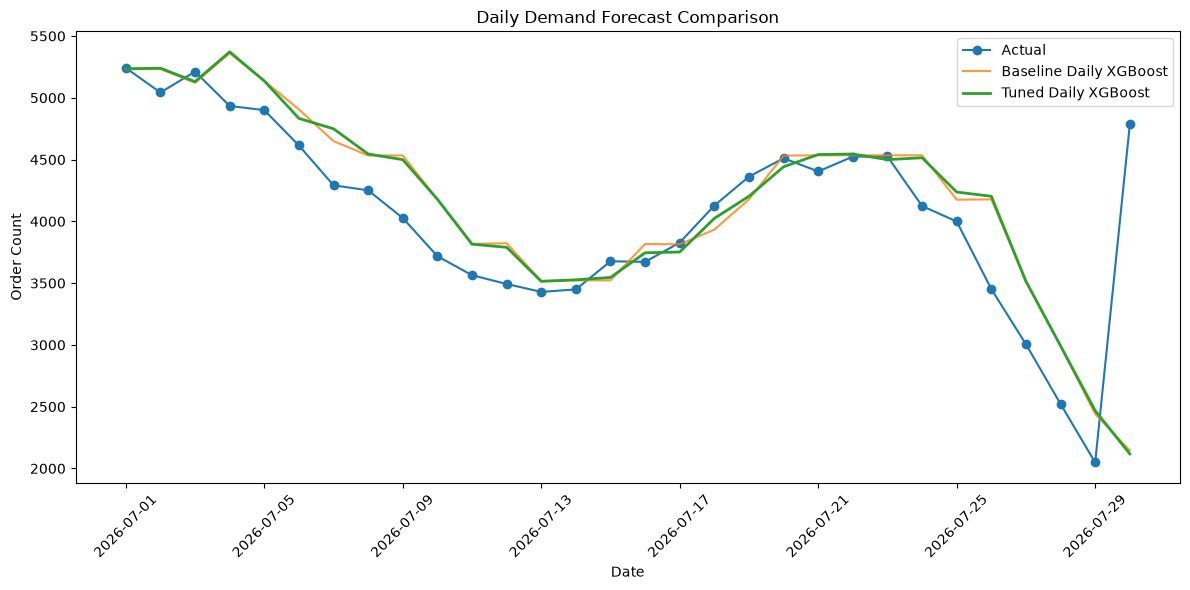

In [34]:
# actual/predicted comparison (Daily)
plt.figure(figsize=(12, 6))
plt.plot(test_daily['date'], test_daily['order_count'], label='Actual', marker='o')
plt.plot(test_daily['date'], daily_preds, label='Baseline Daily XGBoost', linestyle='-', alpha=0.8)
plt.plot(test_daily['date'], test_daily_pred, label='Tuned Daily XGBoost', linestyle='-', linewidth=2)
plt.title('Daily Demand Forecast Comparison')
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [35]:
# r2 score
from sklearn.metrics import r2_score

r2_hourly = r2_score(test_hourly["order_count"], test_pred_hourly)
r2_daily = r2_score(test_daily["order_count"], test_daily_pred)

print("Hourly R2 Score:", r2_hourly)
print("Daily R2 Score:", r2_daily)

Hourly R2 Score: 0.026234984397888184
Daily R2 Score: 0.4073209762573242


6. SARIMA

=== Stationarity Test (ADF) ===
ADF Statistic: -0.6496
P-value: 0.8594
✗ Time series is NOT stationary (d=1 likely needed)


=== Finding Optimal SARIMA Parameters ===
Best SARIMA Order: (2, 2, 2)
Best Seasonal Order: (0, 2, 2, 7)
Best AIC: 1569.98

=== Fitting Final SARIMA Model ===
                                     SARIMAX Results                                     
Dep. Variable:                       order_count   No. Observations:                  167
Model:             SARIMAX(2, 2, 2)x(0, 2, 2, 7)   Log Likelihood                -777.990
Date:                           Fri, 28 Aug 2026   AIC                           1569.980
Time:                                   17:37:04   BIC                           1590.265
Sample:                                        0   HQIC                          1578.223
                                           - 167                                         
Covariance Type:                             opg                                      

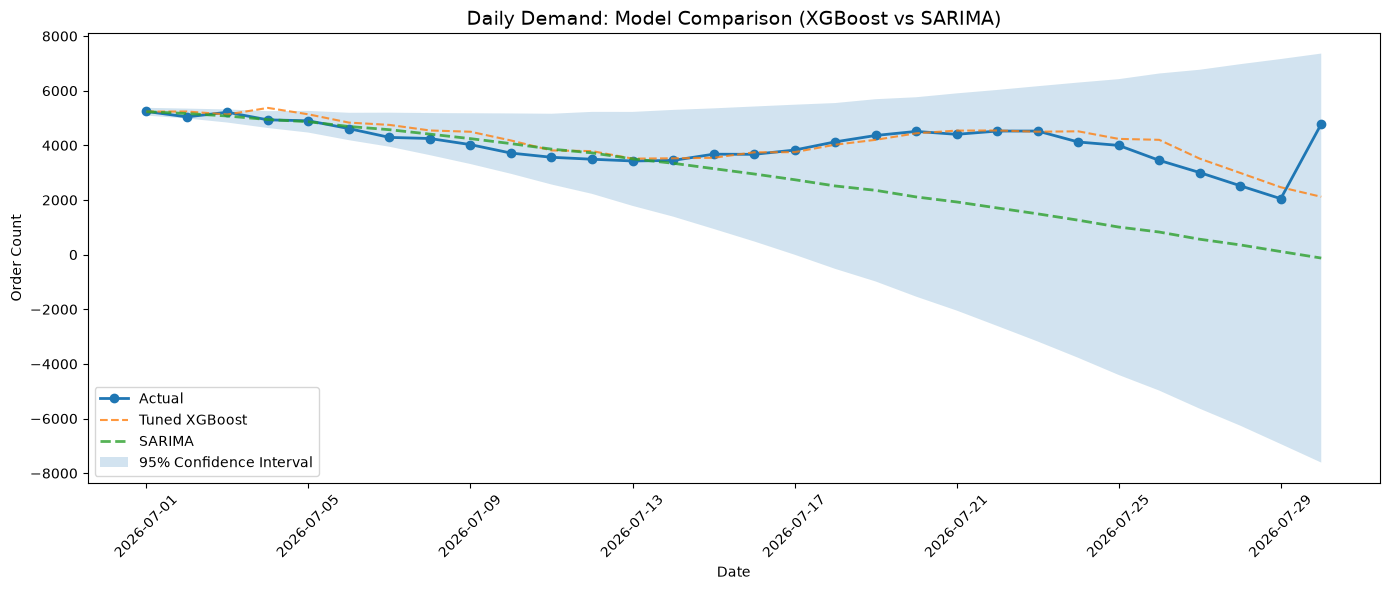


=== SARIMA Diagnostics ===


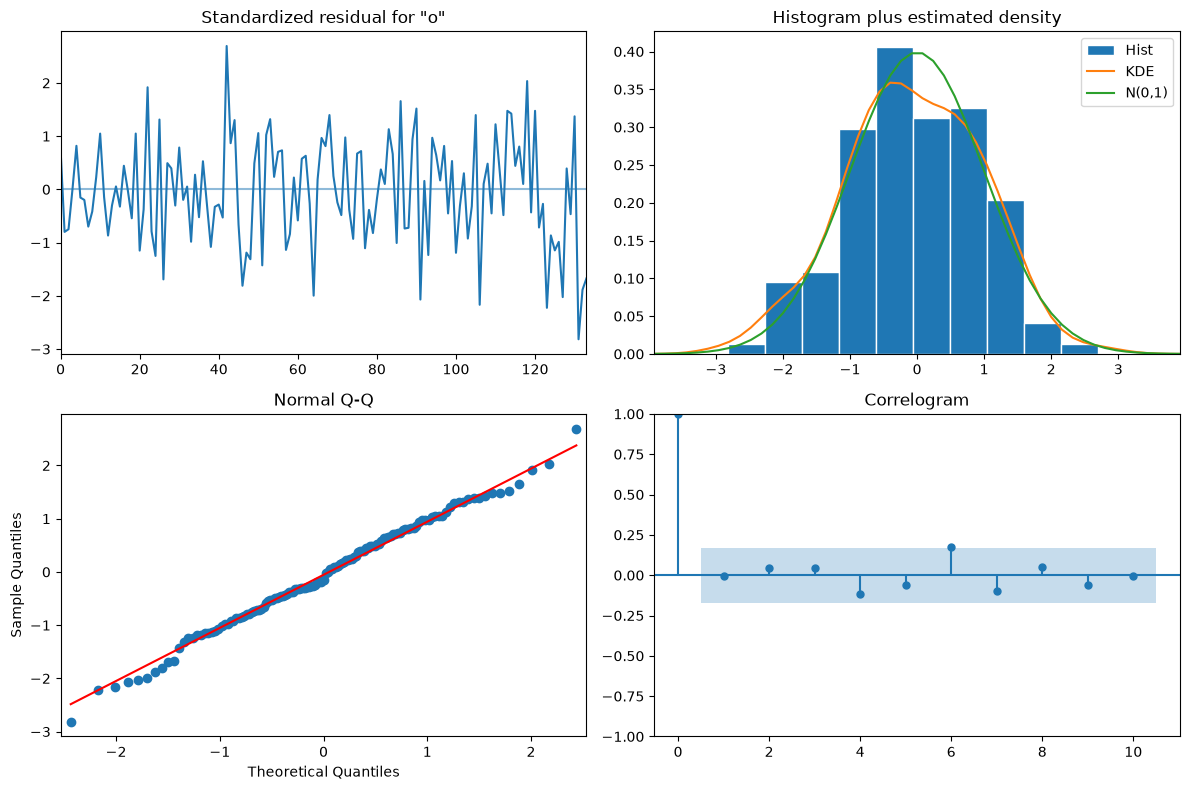

In [37]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from itertools import product
import warnings

warnings.filterwarnings('ignore')
# Step 1: Stationarity Check
print("=== Stationarity Test (ADF) ===")
adf_result = adfuller(daily['order_count'])
print(f"ADF Statistic: {adf_result[0]:.4f}")
print(f"P-value: {adf_result[1]:.4f}")
if adf_result[1] < 0.05:
    print("✓ Time series is stationary (d=0 should work)")
else:
    print("✗ Time series is NOT stationary (d=1 likely needed)\n")

# Step 2: Grid search for optimal SARIMA parameters
print("\n=== Finding Optimal SARIMA Parameters ===")
p = d = q = range(0, 3)
pdq = list(product(p, d, q))
seasonal_pdq = [(x[0], x[1], x[2], 7) for x in product(p, d, q)]  # 7-day seasonality

best_aic = np.inf
best_order = None
best_seasonal_order = None
best_model = None

# Fit on training data
train_daily_combined = pd.concat([train_daily, val_daily])
train_series = train_daily_combined['order_count']

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            model = SARIMAX(
                train_series,
                order=param,
                seasonal_order=param_seasonal,
                enforce_stationarity=False,
                enforce_invertibility=False
            )
            results = model.fit(disp=False, maxiter=200)
            if results.aic < best_aic:
                best_aic = results.aic
                best_order = param
                best_seasonal_order = param_seasonal
                best_model = results
        except:
            continue

print(f"Best SARIMA Order: {best_order}")
print(f"Best Seasonal Order: {best_seasonal_order}")
print(f"Best AIC: {best_aic:.2f}\n")

# Step 3: Fit final SARIMA model on full training data
print("=== Fitting Final SARIMA Model ===")
final_sarima = SARIMAX(
    train_series,
    order=best_order,
    seasonal_order=best_seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)
final_results = final_sarima.fit(disp=False, maxiter=200)
print(final_results.summary())

# Step 4: Make predictions on test set
print("\n=== SARIMA Forecast Results ===")
sarima_forecast = final_results.get_forecast(steps=len(test_daily))
sarima_pred = sarima_forecast.predicted_mean.values
sarima_ci = sarima_forecast.conf_int()

# Step 5: Evaluate performance
sarima_mae = mean_absolute_error(test_daily['order_count'], sarima_pred)
sarima_rmse = np.sqrt(mean_squared_error(test_daily['order_count'], sarima_pred))
sarima_r2 = r2_score(test_daily['order_count'], sarima_pred)

print(f"SARIMA MAE: {sarima_mae:.2f}")
print(f"SARIMA RMSE: {sarima_rmse:.2f}")
print(f"SARIMA R²: {sarima_r2:.4f}")

# Step 6: Compare with baseline models
print("\n=== Model Comparison ===")
comparison_df = pd.DataFrame({
    'Model': ['Baseline XGBoost', 'Tuned XGBoost', 'SARIMA'],
    'MAE': [daily_mae, daily_test_mae, sarima_mae],
    'RMSE': [daily_rmse, daily_test_rmse, sarima_rmse],
    'R²': [daily_r2, daily_test_r2, sarima_r2]
})
print(comparison_df)

# Step 7: Visualization
plt.figure(figsize=(14, 6))
plt.plot(test_daily['date'], test_daily['order_count'], label='Actual', marker='o', linewidth=2)
plt.plot(test_daily['date'], test_daily_pred, label='Tuned XGBoost', linestyle='--', alpha=0.8)
plt.plot(test_daily['date'], sarima_pred, label='SARIMA', linestyle='--', linewidth=2, alpha=0.8)
plt.fill_between(test_daily['date'], 
                  sarima_ci.iloc[:, 0], 
                  sarima_ci.iloc[:, 1], 
                  alpha=0.2, label='95% Confidence Interval')
plt.title('Daily Demand: Model Comparison (XGBoost vs SARIMA)', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Order Count')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Step 8: Diagnostics
print("\n=== SARIMA Diagnostics ===")
final_results.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()